# Fundamental diagram experiments
1. **Calibrated FDs vs data:** scatter flow-density points against the FD implied by the static and dynamic METANET calibrations (`plotting.plot_fd_panels`).
2. **FD regression on the observed data** (`fd_regression.py`, every fit through `optimization_utils.fit_fd`):
   - **Rolling FD:** a static FD fit to each sliding window, in sequence.
   - **Drifting FD:** one FD fit to the whole period, with parameters that change over time.
   - **Cross-validation:** static and drifting FDs fit to different subsets of the data and scored on held-out chunks.

In [156]:
# Find the repo root (the folder containing src/paths.py), put src/ on the import
# path, and run from the repo root so relative data/ and calibration/ paths resolve.
import os, sys
_root = os.path.abspath(os.getcwd())
while not os.path.exists(os.path.join(_root, "src", "paths.py")):
    _parent = os.path.dirname(_root)
    if _parent == _root:
        raise RuntimeError("Could not find src/paths.py above the working directory")
    _root = _parent
if os.path.join(_root, "src") not in sys.path:
    sys.path.insert(0, os.path.join(_root, "src"))
os.chdir(_root)

In [157]:
%load_ext autoreload
%autoreload 2

import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from optimization_utils import smooth_inflow, FD_KEYS
from simulation_utils import run_metanet_sim
from param_loader import METANET_Params
from plotting import plot_fd_panels
from fd_regression import (rolling_fd_fit, plot_rolling_fd_params, plot_rolling_fd_curves,
                           drifting_fd_table, plot_drifting_fd,
                           cross_validate_fd, cv_error_table, cv_segment_table,
                           plot_cv_param_distributions, plot_cv_capacity)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Load data

In [158]:
path_id = "i24/i24_11_30"
data_path = f"data/{path_id}"
calib_path = f"calibration/{path_id}"

lanes = np.load(f"{data_path}/lane_mapping.npy")
rho_hat = np.load(f"{data_path}/rho_hat.npy")   # total density (veh/km), includes boundary cells
q_hat = np.load(f"{data_path}/q_hat.npy")       # total flow (veh/h), includes boundary cells
rho_hat = np.where(rho_hat == 0.0, 1e-3, rho_hat)
q_hat = np.where(q_hat == 0.0, 1e-3, q_hat)
v_hat = q_hat / rho_hat

T = 10/3600
l = 0.4
num_timesteps = rho_hat.shape[0]
num_calibrated_segments = rho_hat.shape[1] - 2
seg_lanes = lanes[1:-1]

downstream_density = smooth_inflow(rho_hat[:, -1] / lanes[-1])
data_inflow = smooth_inflow(q_hat[:, 0])
init_traffic_state = (rho_hat[0, 1:-1] / seg_lanes, v_hat[0, 1:-1], data_inflow[0], 0)
print(rho_hat.shape, num_calibrated_segments)

(360, 16) 14


## Load calibrations

In [159]:
control_h = 90
static_params = METANET_Params(f"{calib_path}/calibration_static/fixed_ramping",
                               num_segments=num_calibrated_segments).get_params()
dynamic_params = METANET_Params(f"{calib_path}/calibration_dynamic_smooth", control_h=control_h,
                                num_timesteps=num_timesteps,
                                num_segments=num_calibrated_segments).get_params()

## Flow-density states
Both helpers return per-lane `(rho, q, v)` arrays of shape `(num_timesteps, num_segments)` for the calibrated segments.

In [160]:
def observed_states(rho_hat, q_hat, lanes):
    """Per-lane density/flow/speed of the calibrated segments (boundary cells dropped)."""
    seg_lanes = np.asarray(lanes)[1:-1]
    rho = rho_hat[:, 1:-1] / seg_lanes
    q = q_hat[:, 1:-1] / seg_lanes
    return rho, q, q / rho


def model_states(params, T=T, l=l, init_traffic_state=init_traffic_state, data_inflow=data_inflow,
                 downstream_density=downstream_density, seg_lanes=seg_lanes):
    """Per-lane density/flow/speed from an open-loop METANET run with the calibrated params."""
    rho, v, _, _ = run_metanet_sim(T, l, init_traffic_state, data_inflow, downstream_density, params,
                                   vsl_speeds=None,
                                   lanes={i: seg_lanes[i] for i in range(len(seg_lanes))},
                                   plotting=True, real_data=True)
    rho, v = rho[:-1], v[:-1]   # drop the final state so the length matches the data
    return rho, rho * v, v

## Static calibration visualization

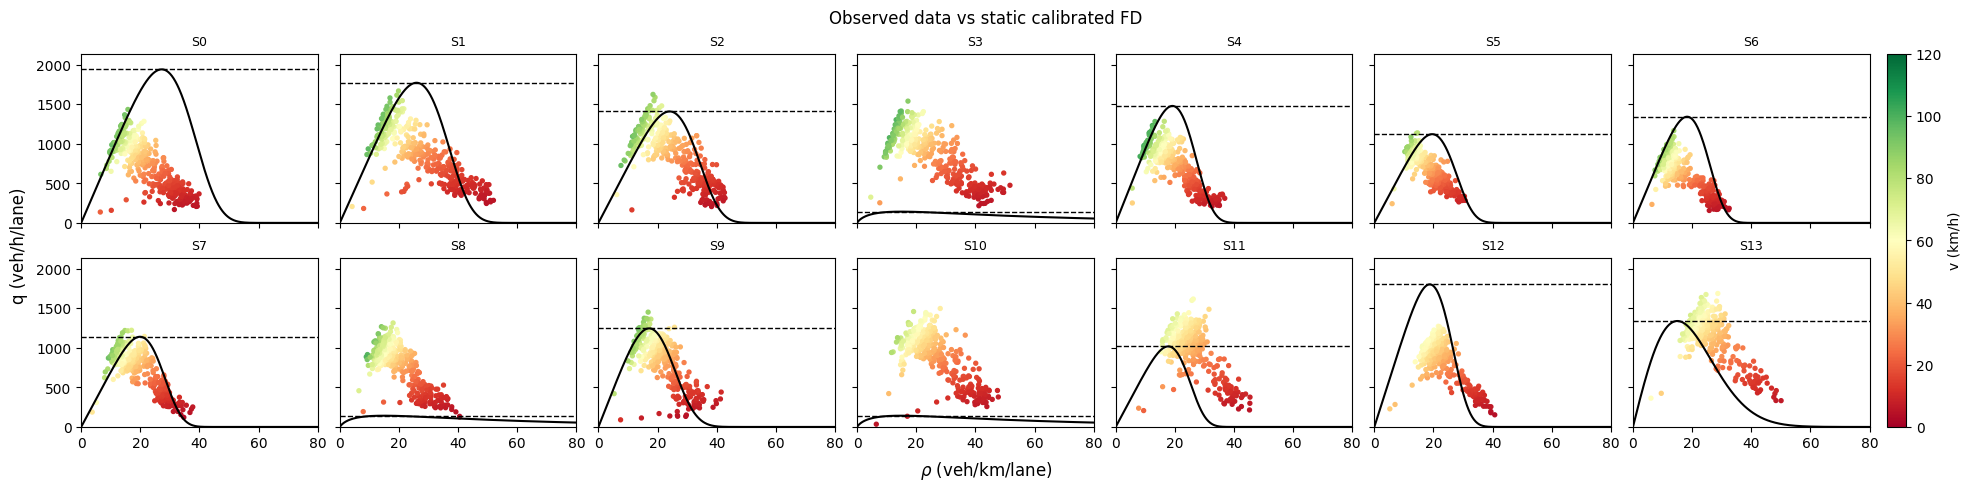

In [161]:
obs = observed_states(rho_hat, q_hat, lanes)
plot_fd_panels(static_params, *obs, title="Observed data vs static calibrated FD");

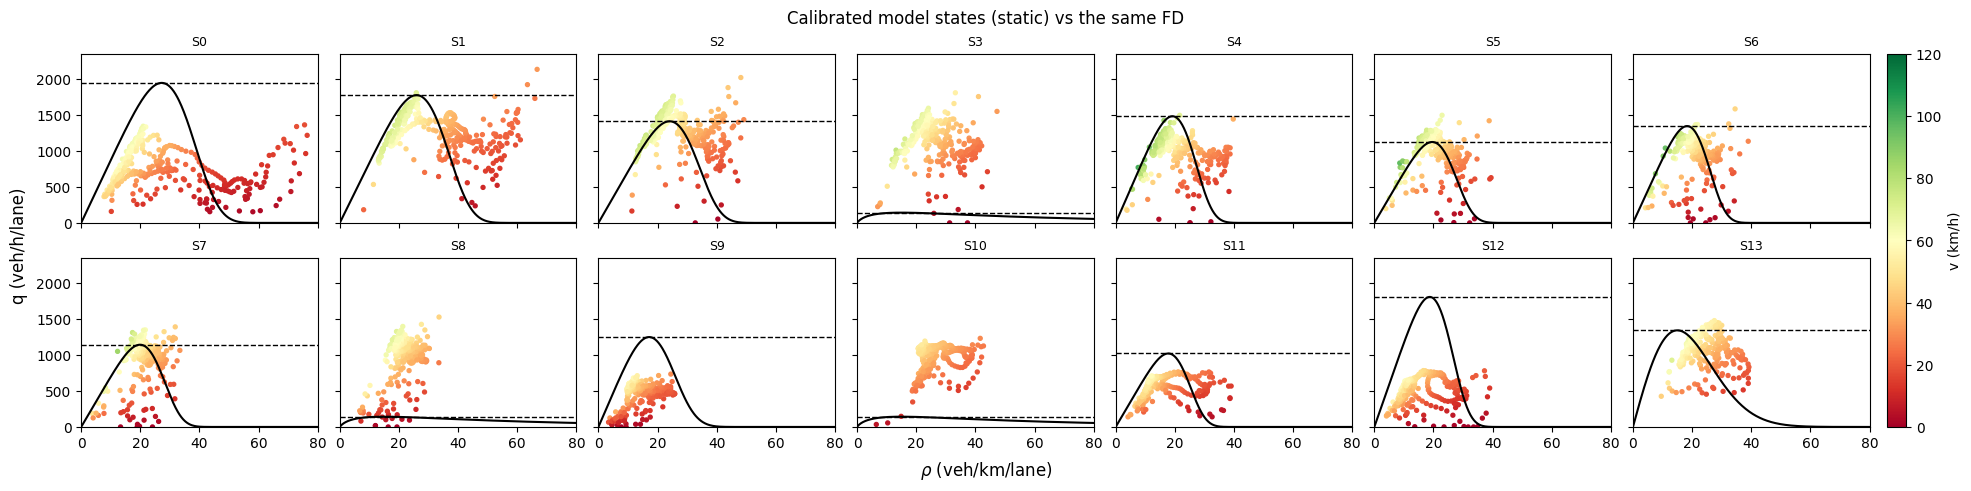

In [162]:
static_sim = model_states(static_params)
plot_fd_panels(static_params, *static_sim, title="Calibrated model states (static) vs the same FD");

## Dynamic calibration visualization
Rows are parameter windows of `control_h` timesteps; columns are segments. Pass `segments=` / `windows=` to plot a subset (useful for short horizons).

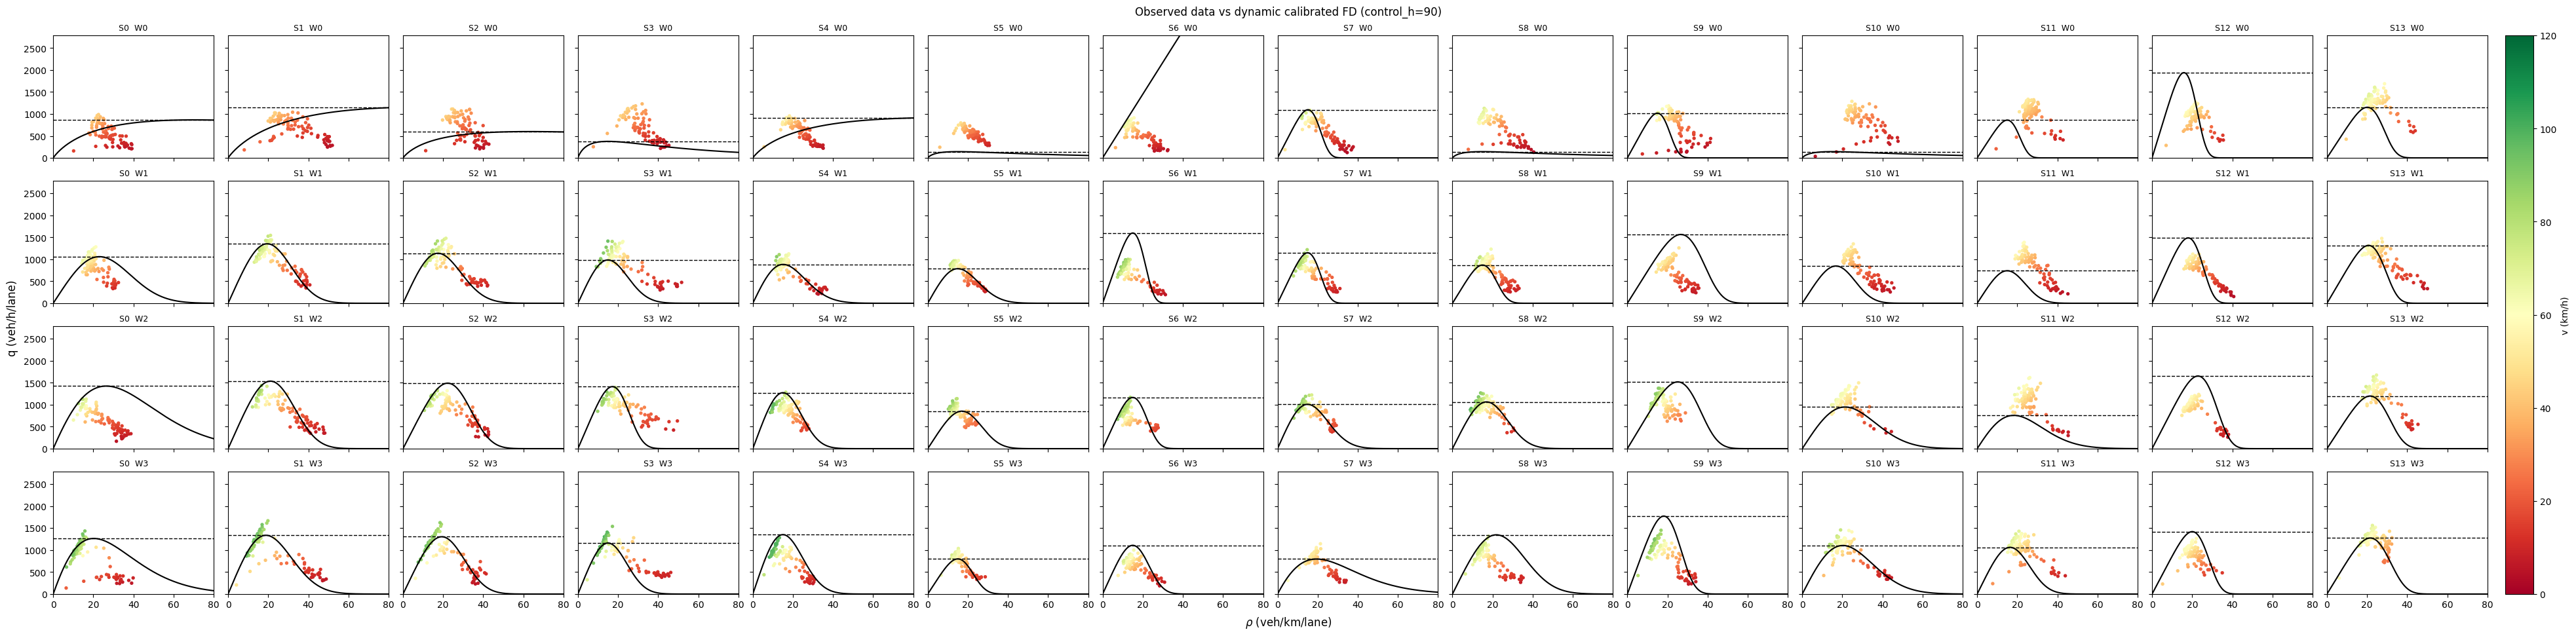

In [163]:
plot_fd_panels(dynamic_params, *obs, control_h=control_h,
               title=f"Observed data vs dynamic calibrated FD (control_h={control_h})");

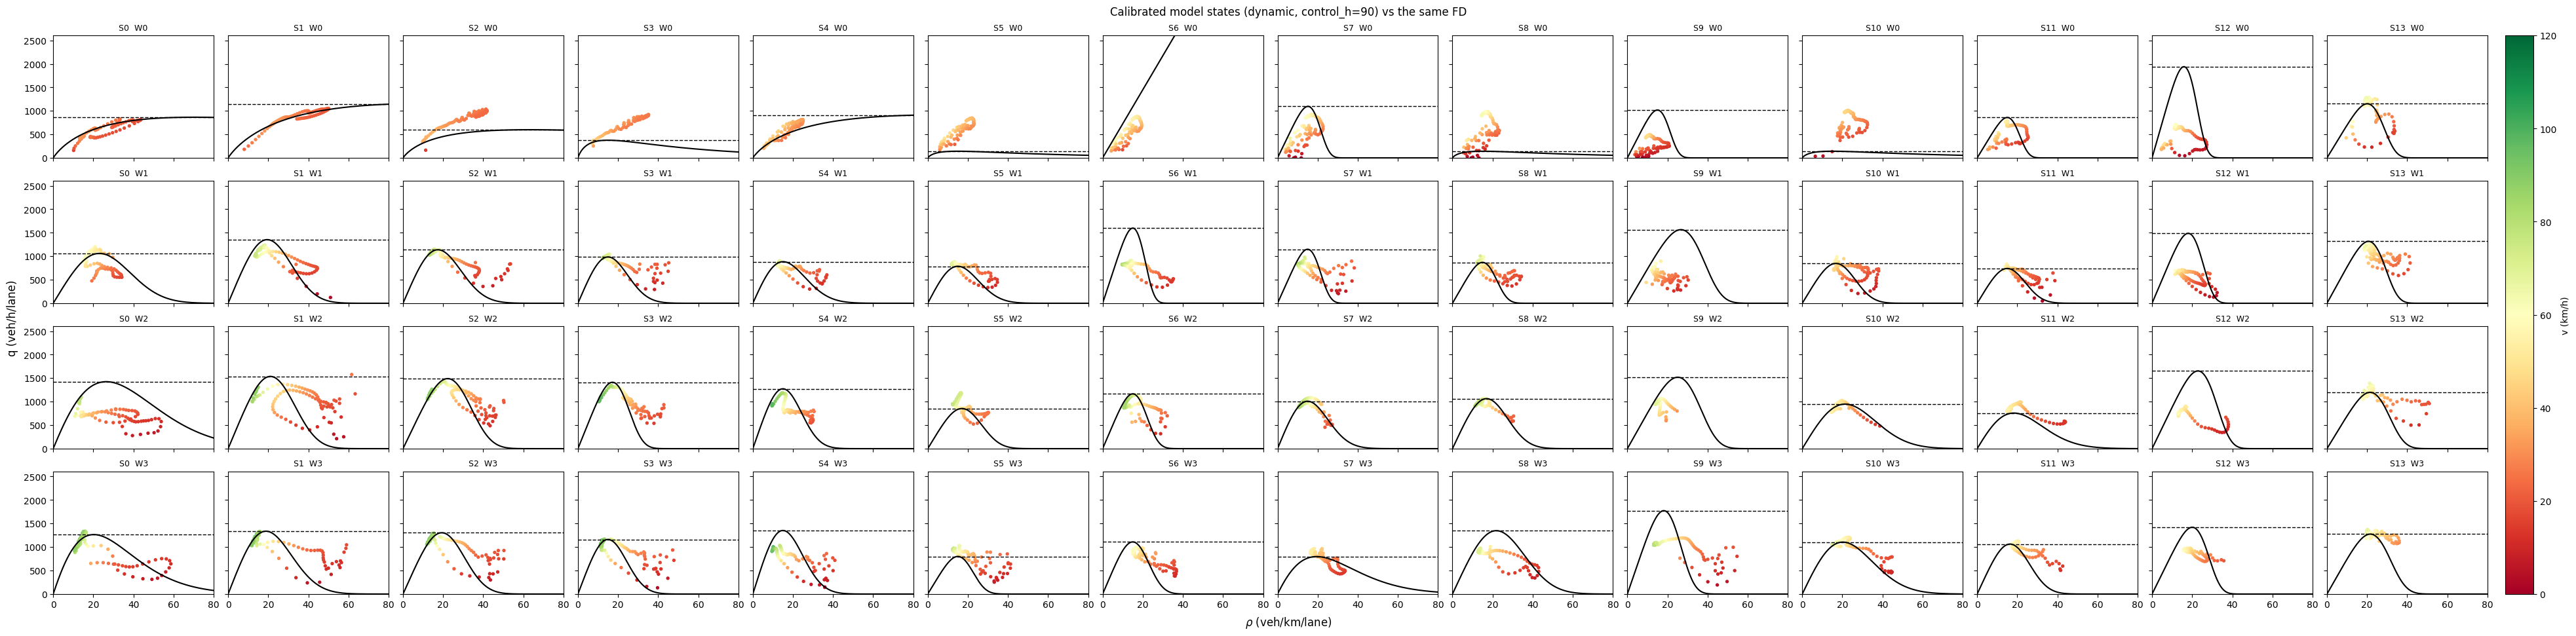

In [164]:
dynamic_sim = model_states(dynamic_params)
plot_fd_panels(dynamic_params, *dynamic_sim, control_h=control_h,
               title=f"Calibrated model states (dynamic, control_h={control_h}) vs the same FD");

## Rolling FD fit
For each segment, fit a static FD (`fit_fd`) to the observed per-lane data in the window `[s, s + H)`, then slide the start by `k` timesteps until the window reaches the end of the period.

In [136]:
steps_per_min = int(round(1 / (T * 60)))   # 6 timesteps per minute at T = 10 s
H_fit = 20 * steps_per_min                  # 20 min window
k_fit = 1 * steps_per_min                   # 1 min shift

rho_obs, q_obs, _ = obs
fit_starts, rolling_fits = rolling_fd_fit(rho_obs, q_obs, H_fit, k_fit)
print(f"{len(fit_starts)} windows x {num_calibrated_segments} segments")

41 windows x 14 segments


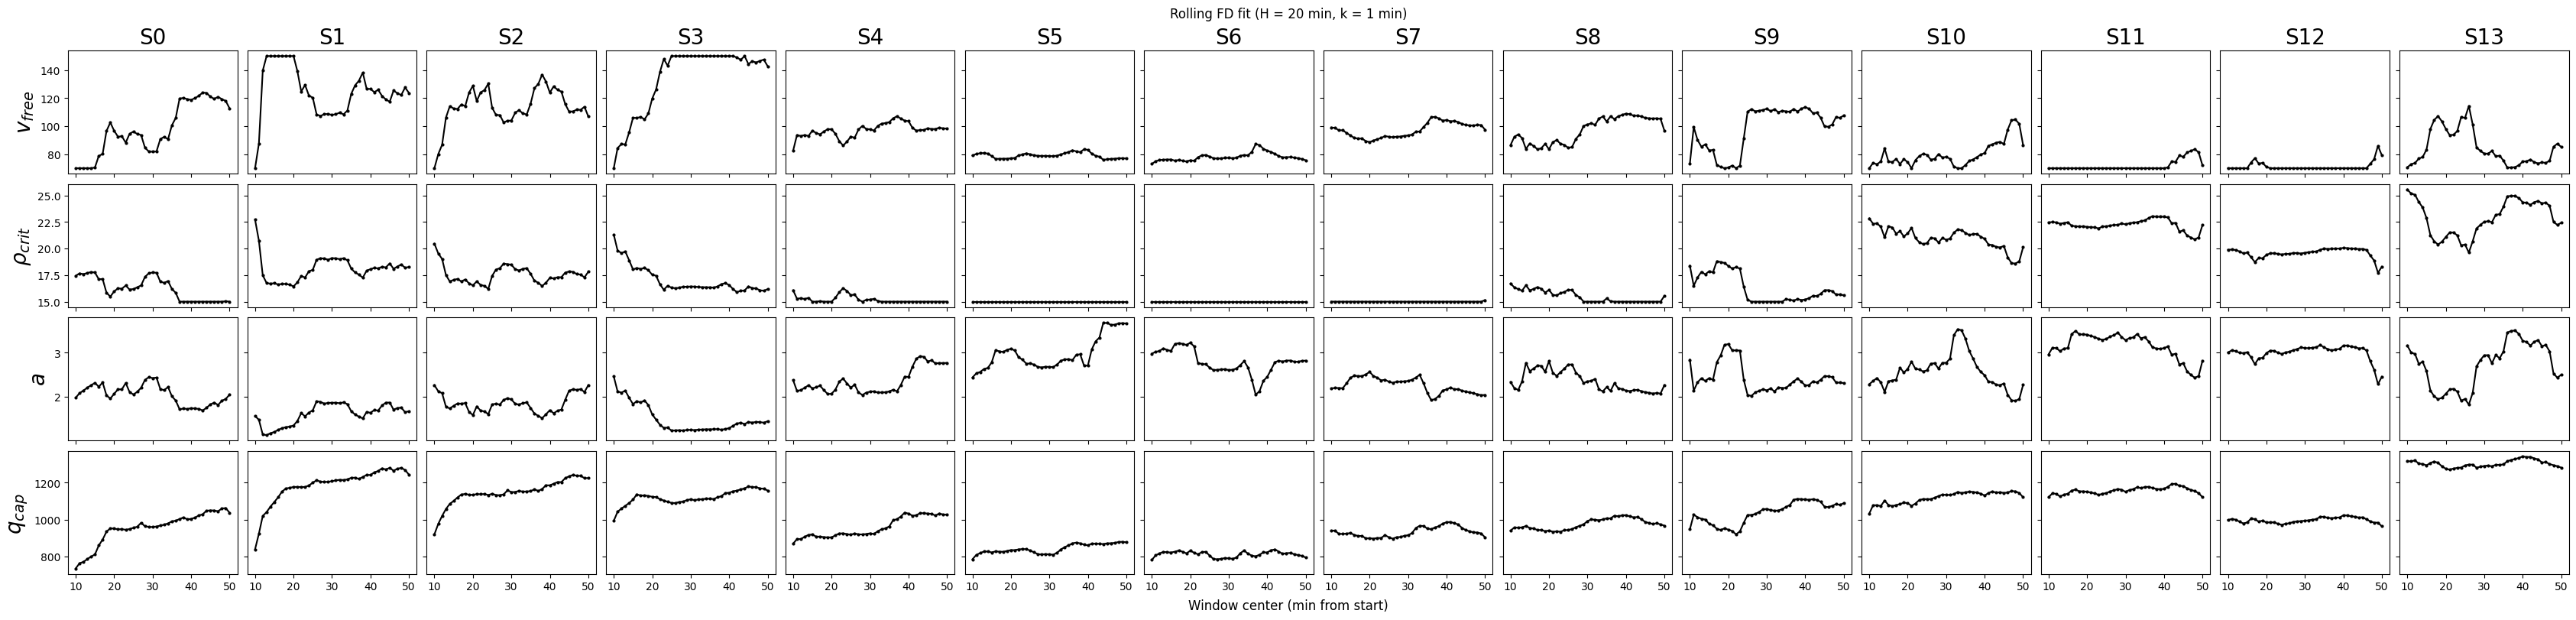

In [140]:
plot_rolling_fd_params(fit_starts, rolling_fits, H_fit, k_fit, dt_min=T * 60, ref_params=None);

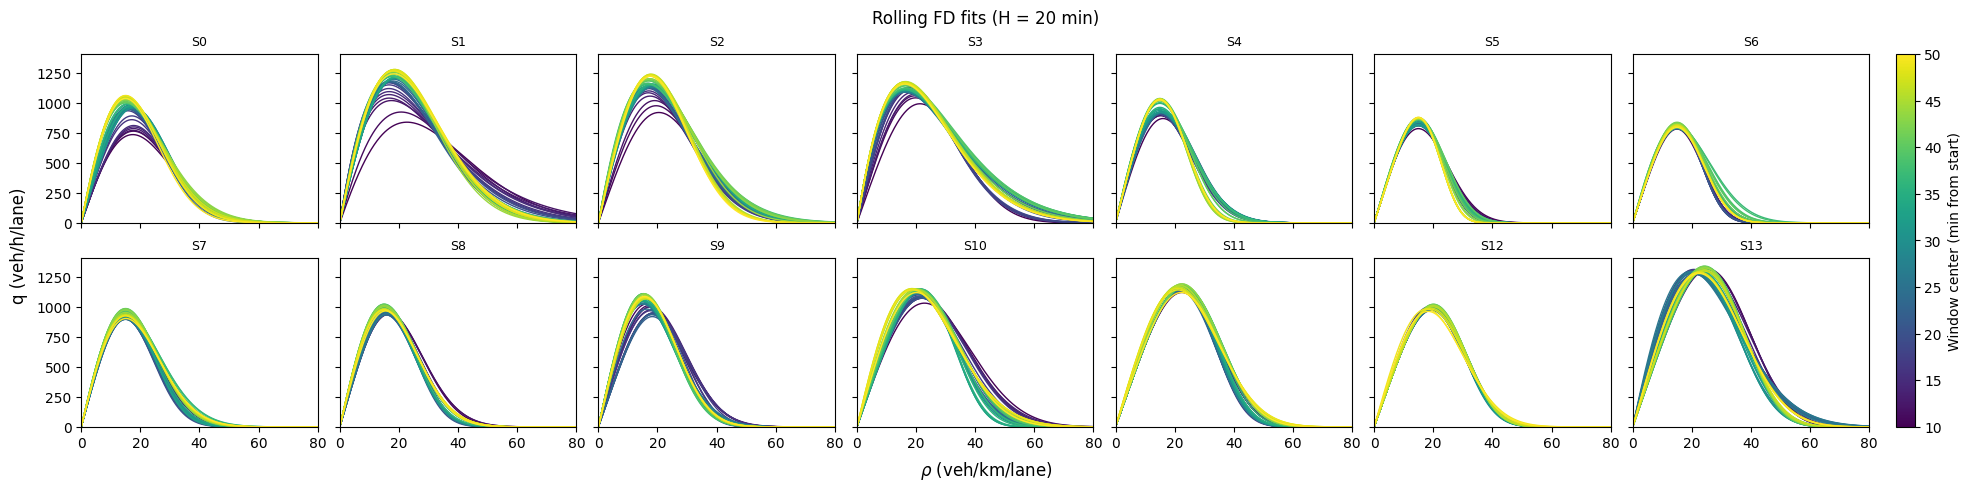

In [141]:
plot_rolling_fd_curves(fit_starts, rolling_fits, H_fit, dt_min=T * 60);

## Drifting FD fit
Instead of fitting separate windows, fit one FD per segment to all the observed data, but let chosen parameters change over time. `drift` maps each drifting parameter to the degree of its polynomial path; parameters left out stay constant (but are still fitted):
- `{}`: a static FD.
- `{"v_free": 1}`: v_free moves in a straight line from the start to the end of the period; p_crit and a are constant.
- `{"v_free": 2, "p_crit": 2, "a": 2}`: all three can curve once, e.g. rise then fall.

Each drifting parameter's path is a Bernstein polynomial: a weighted average of `degree + 1` control points, each kept within the `fit_fd` bounds, so the whole path stays within them.

The table shows each parameter's path as an ordinary polynomial, p(t) = c0 + c1·t + c2·t² + …, with t in hours from the start, so c0 is the value at the start and c1 is the initial rate of change (per hour).

Each segment is also fit with a static FD for comparison. `drift_stats` holds how much the drifting FD reduces the fit error. The `F` statistic measures how much better the drifting fit is per extra parameter. `p_naive` treats every 10 s observation as independent, which they aren't, so it overstates confidence. Read it as a rough guide; the cross-validation section below gives a fairer comparison.

In [165]:
t_min = np.arange(num_timesteps) * T * 60    # minutes from start
drift = {"v_free": 1, "p_crit": 1, "a": 1}   # {parameter: polynomial degree}; parameters left out stay constant
drift_coefs, drift_fits, drift_stats = drifting_fd_table(rho_obs, q_obs, t_min, drift)

# p(t) = c0 + c1 t + c2 t^2 + ..., t in hours from the start
drift_coefs.round(2)

v_free        p_crit           a      
             c0     c1     c0    c1    c0    c1
segment                                        
0         70.00  49.57  17.51 -2.52  1.93  0.21
1        150.00 -52.77  16.77  3.17  0.84  1.47
2        150.00 -52.68  15.43  3.07  1.06  1.32
3         73.04  77.17  20.54 -4.73  2.13 -0.83
4         98.94  -0.76  15.00 -0.00  1.75  1.06
5         80.66  -5.13  15.00  0.00  1.95  1.98
6         71.76   7.83  15.00  0.00  2.96 -0.42
7         94.99   4.71  15.00  0.00  2.29 -0.26
8        104.69 -14.84  15.00  0.90  1.72  1.15
9         70.00  44.36  18.17 -3.07  2.56 -0.11
10        92.04 -20.31  20.32  1.09  1.38  2.11
11        70.00   0.00  22.34  0.22  2.90  0.26
12        70.00   1.32  20.10 -1.17  2.86  0.20
13        70.25  16.53  25.35 -3.53  3.05 -0.47

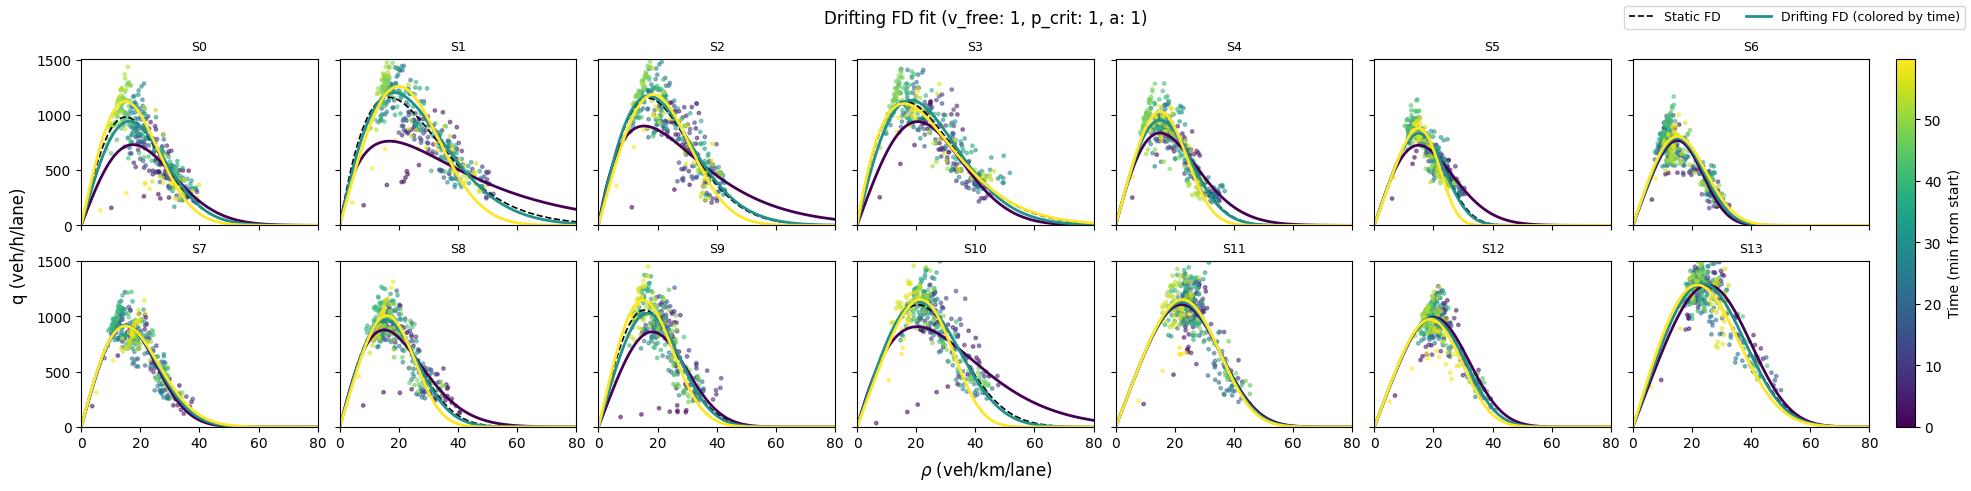

In [166]:
plot_drifting_fd(rho_obs, q_obs, t_min, drift_fits);

### Choosing the degree
Higher degrees always fit at least as well, so compare how much each extra degree buys. If going from degree d to d + 1 barely reduces the error, degree d is enough.

In [167]:
degree_comparison = pd.DataFrame({
    f"degree {d}": drifting_fd_table(rho_obs, q_obs, t_min, {key: d for key in FD_KEYS})[2]["RSS_reduction_%"]
    for d in (0, 1, 2, 3)
})
degree_comparison.round(1)   # % reduction in fit error vs the static FD

,degree 0,degree 1,degree 2,degree 3
segment,,,,
0,0.0,13.6,18.6,24.6
1,0.0,26.3,41.2,45.2
2,0.0,7.6,12.2,16.2
3,0.0,7.1,7.7,10.9
4,0.0,10.2,12.8,15.3
5,0.0,11.5,14.0,15.5
6,0.0,1.2,6.0,8.5
7,0.0,0.5,4.7,5.9
8,0.0,4.5,9.2,21.9


### Cross-validation
Split the hour into chunks of `block_min` minutes. For each chunk:
1. Hold that chunk out as the **test** set.
2. Also drop `gap_min` minutes on each side of it, because readings right next to the test chunk are nearly identical to it and would leak information.
3. Fit every model in `cv_models` to the remaining data (the **training** set). Each model is a `drift` dict, as above; the one with `{}` is the static reference.
4. Record each model's error (RMSE, veh/h/lane) on the training set and on the held-out chunk.

Training error always goes down as the model gets more flexible. Test error only goes down if the extra flexibility captures something real; if it is only fitting noise, test error goes up. So **a drifting FD with lower test error than the static FD is evidence the FD really drifted**, and the model with the lowest test error is the best choice.

The drifting paths are always defined over the full hour, so the coefficients from every fold are directly comparable. Holding out the first or last chunk means extending the path past the training data, so high degrees can score badly there.

In [168]:
cv_models = {
    "Static FD": {},
    "Drifting FD (degree 1)": {"v_free": 1, "p_crit": 1, "a": 1},
    "Drifting FD (degree 2)": {"v_free": 2, "p_crit": 2, "a": 2},
    "Drifting FD (degree 3)": {"v_free": 3, "p_crit": 3, "a": 3},
}
cv_results = cross_validate_fd(rho_obs, q_obs, t_min, cv_models, block_min=3, gap_min=1)
print(f"{len(cv_results['folds'])} folds x {len(cv_results['segments'])} segments")

# averaged over all folds and all segments (veh/h/lane)
cv_error_table(cv_results).round(1) #  segments=[1, 3, 5]

20 folds x 14 segments


,Avg train RMSE,Train improvement vs static (%),Avg test RMSE,Test improvement vs static (%)
model,,,,
Static FD,153.2,0.0,151.5,0.0
Drifting FD (degree 1),146.3,4.5,157.3,-3.8
Drifting FD (degree 2),138.8,9.4,164.8,-8.8
Drifting FD (degree 3),134.9,11.9,169.3,-11.7


In [169]:
# Average test RMSE per segment, lowest highlighted: drift can matter in some segments and not others
cv_segment_table(cv_results)

,Static FD,Drifting FD (degree 1),Drifting FD (degree 2),Drifting FD (degree 3)
segment,,,,
0,165.2,162.5,178.7,178.7
1,176.8,177.3,182.1,190.4
2,177.6,185.6,198.1,190.7
3,160.7,157.2,167.4,169.8
4,130.3,130.7,144.2,146.1
5,112.2,106.4,111.9,118.6
6,131.5,141.5,142.5,149.6
7,124.7,130.0,142.8,155.4
8,138.8,147.8,153.3,148.4


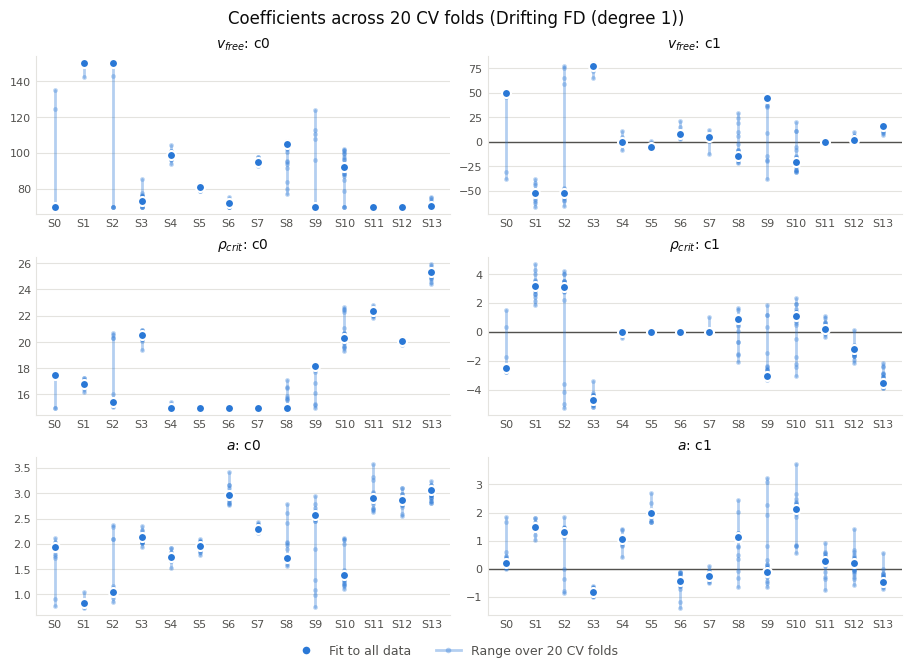

In [170]:
plot_cv_param_distributions(cv_results, "Drifting FD (degree 1)");

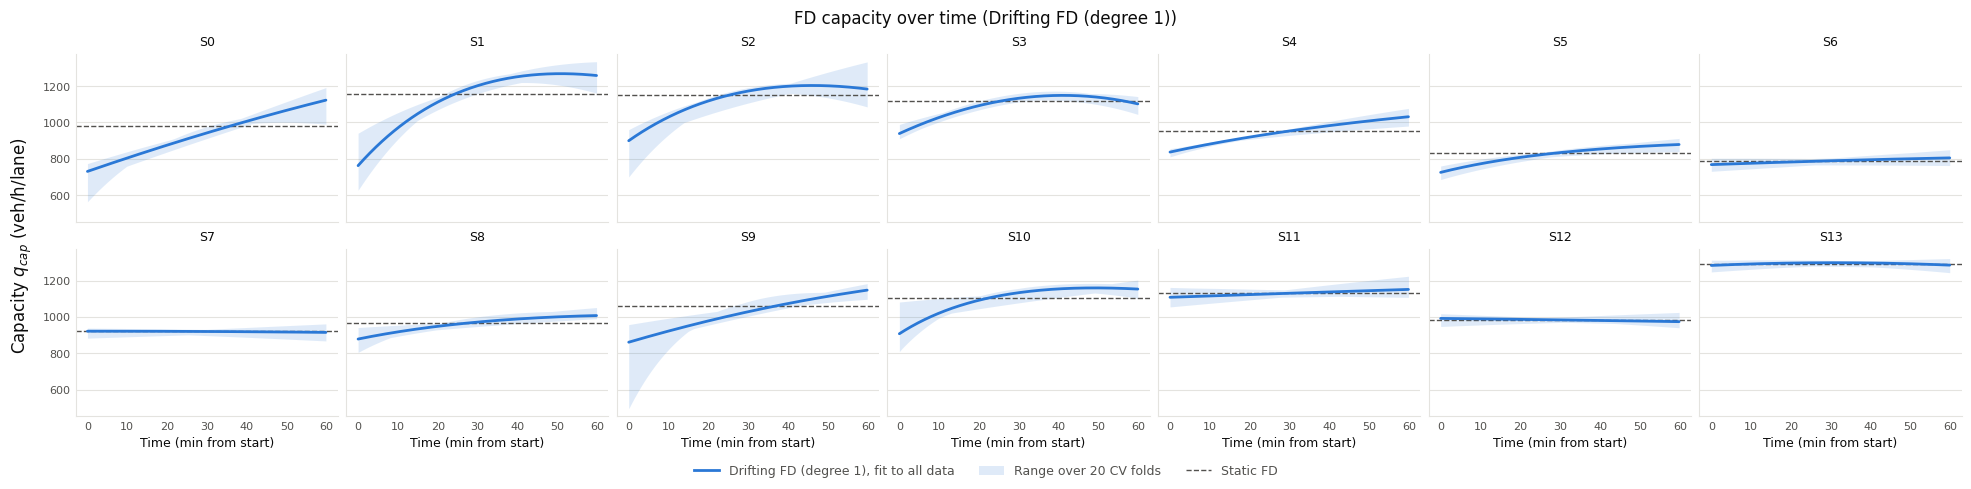

In [171]:
plot_cv_capacity(cv_results, t_min, "Drifting FD (degree 1)");

### Cross-validation with drifting only one parameter at a time

In [172]:
cv_models_ablation = {
    "Static FD": {},
    "Drifting FD (v_free, 1)": {"v_free": 1},
    "Drifting FD (p_crit, 1)": {"p_crit": 1},
    "Drifting FD (a, 1)": {"a": 1},
    "Drifting FD (v_free, 2)": {"v_free": 2},
    "Drifting FD (p_crit, 2)": {"p_crit": 2},
    "Drifting FD (a, 2)": {"a": 2},
    "Drifting FD (all, 1)": {"v_free": 1, "p_crit": 1, "a": 1},
    "Drifting FD (all, 2)": {"v_free": 2, "p_crit": 2, "a": 2},
}

cv_results_ablation = cross_validate_fd(rho_obs, q_obs, t_min, cv_models_ablation, block_min=3, gap_min=1)
print(f"{len(cv_results_ablation['folds'])} folds x {len(cv_results_ablation['segments'])} segments")

# averaged over all folds and all segments (veh/h/lane)
cv_error_table(cv_results_ablation).round(1) #  segments=[1, 3, 5]

20 folds x 14 segments


,Avg train RMSE,Train improvement vs static (%),Avg test RMSE,Test improvement vs static (%)
model,,,,
Static FD,153.2,0.0,151.5,0.0
"Drifting FD (v_free, 1)",150.7,1.6,154.0,-1.6
"Drifting FD (p_crit, 1)",152.3,0.6,154.0,-1.7
"Drifting FD (a, 1)",148.1,3.3,152.3,-0.6
"Drifting FD (v_free, 2)",148.0,3.4,157.5,-4.0
"Drifting FD (p_crit, 2)",151.3,1.3,157.5,-4.0
"Drifting FD (a, 2)",143.7,6.2,156.7,-3.4
"Drifting FD (all, 1)",146.3,4.5,157.3,-3.8
"Drifting FD (all, 2)",138.8,9.4,164.8,-8.8


In [173]:
# Average test RMSE per segment, lowest highlighted
cv_segment_table(cv_results_ablation)

,Static FD,"Drifting FD (v_free, 1)","Drifting FD (p_crit, 1)","Drifting FD (a, 1)","Drifting FD (v_free, 2)","Drifting FD (p_crit, 2)","Drifting FD (a, 2)","Drifting FD (all, 1)","Drifting FD (all, 2)"
segment,,,,,,,,,
0,165.2,161.4,166.5,160.0,168.2,174.4,172.7,162.5,178.7
1,176.8,174.3,180.0,171.9,175.0,180.3,165.3,177.3,182.1
2,177.6,180.0,181.8,176.9,180.6,182.4,181.9,185.6,198.1
3,160.7,161.6,161.8,162.4,159.6,160.9,163.2,157.2,167.4
4,130.3,131.5,131.9,125.6,131.5,133.8,129.2,130.7,144.2
5,112.2,116.6,112.2,104.9,119.0,112.5,105.4,106.4,111.9
6,131.5,135.5,131.5,134.7,133.8,131.8,141.8,141.5,142.5
7,124.7,127.1,125.5,126.4,129.3,127.3,127.8,130.0,142.8
8,138.8,142.5,141.4,143.1,148.7,143.9,150.0,147.8,153.3
